# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Розмір набору:", iris_df.shape)
iris_df.head()

Розмір набору: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

Ознаки для кластеризації: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']


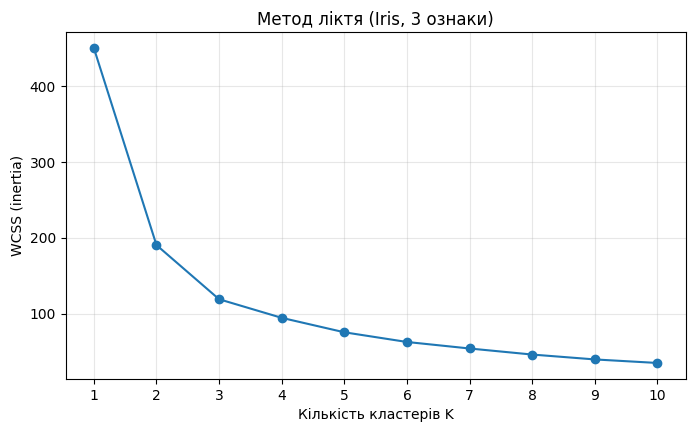

,K,WCSS,"Зменшення, %"
0,1,450.00,NaN
1,2,190.47,57.7
2,3,119.14,37.4
3,4,94.64,20.6
4,5,75.63,20.1
5,6,62.87,16.9
6,7,54.28,13.7
7,8,46.31,14.7
8,9,39.89,13.9
9,10,35.23,11.7


In [3]:
# Для кластеризації беремо три перші ознаки Iris:
# sepal length, sepal width, petal length (цільову змінну species не використовуємо)
iris_features = iris.feature_names[:3]
print("Ознаки для кластеризації:", iris_features)

scaler_iris = StandardScaler()
X_iris = scaler_iris.fit_transform(iris_df[iris_features])

# Метод ліктя: WCSS (inertia) для K = 1..10
wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_iris)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(list(k_range), wcss, marker='o')
plt.title('Метод ліктя (Iris, 3 ознаки)')
plt.xlabel('Кількість кластерів K')
plt.ylabel('WCSS (inertia)')
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

# Відносне зменшення WCSS при переході K-1 → K
wcss_table = pd.DataFrame({'K': list(k_range), 'WCSS': wcss})
wcss_table['Зменшення, %'] = (-wcss_table['WCSS'].pct_change() * 100).round(1)
display(wcss_table.round(2))

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

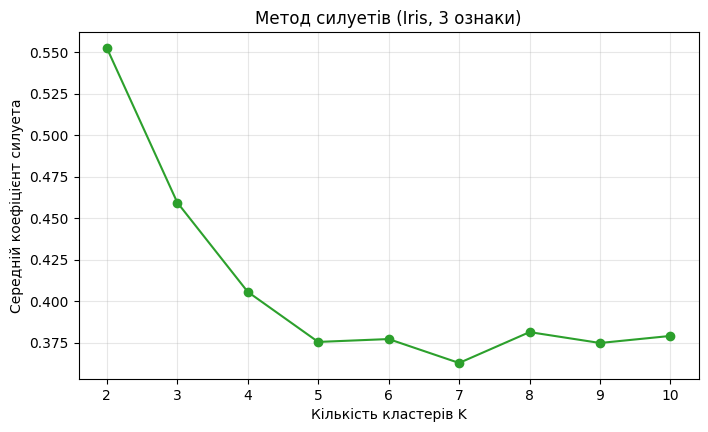

K,2,3,4,5,6,7,8,9,10
Silhouette,0.552,0.459,0.406,0.375,0.377,0.363,0.381,0.375,0.379


Максимальний силует: K = 2 (0.552)


In [4]:
silhouette_scores = []
k_range_sil = range(2, 11)
for k in k_range_sil:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_iris)
    silhouette_scores.append(silhouette_score(X_iris, labels))

plt.figure(figsize=(8, 4.5))
plt.plot(list(k_range_sil), silhouette_scores, marker='o', color='tab:green')
plt.title('Метод силуетів (Iris, 3 ознаки)')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(list(k_range_sil))
plt.grid(alpha=0.3)
plt.show()

sil_table = pd.DataFrame({'K': list(k_range_sil), 'Silhouette': silhouette_scores}).round(3)
display(sil_table.set_index('K').T)
best_k_sil = sil_table.loc[sil_table['Silhouette'].idxmax(), 'K']
print(f"Максимальний силует: K = {best_k_sil} ({sil_table['Silhouette'].max():.3f})")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

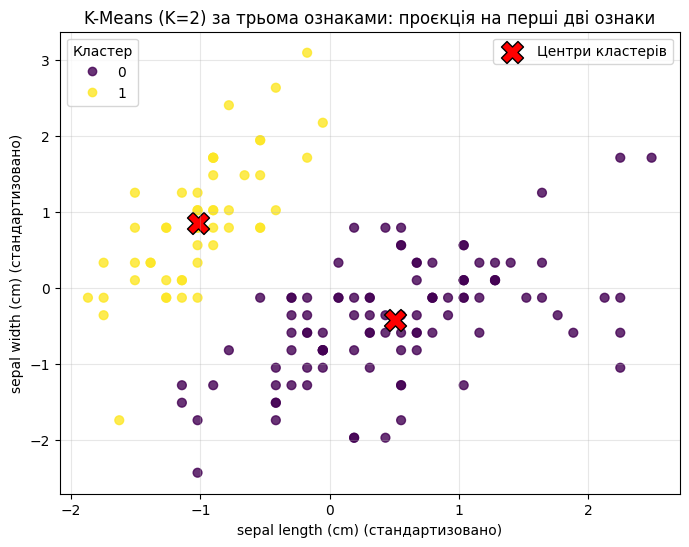

Розміри кластерів: {0: 100, 1: 50}
Координати центрів (стандартизовані, усі три ознаки):


,sepal length (cm),sepal width (cm),petal length (cm)
0,0.507,-0.427,0.652
1,-1.015,0.853,-1.305


Координати центрів у вихідних одиницях (см):


,sepal length (cm),sepal width (cm),petal length (cm)
0,6.26,2.87,4.91
1,5.01,3.43,1.46


In [5]:
kmeans_final = KMeans(n_clusters=2, n_init=10, random_state=42)
iris_labels = kmeans_final.fit_predict(X_iris)
centers = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_iris[:, 0], X_iris[:, 1], c=iris_labels, cmap='viridis', s=40, alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=250,
            edgecolor='black', label='Центри кластерів')
plt.title('K-Means (K=2) за трьома ознаками: проєкція на перші дві ознаки')
plt.xlabel(f'{iris_features[0]} (стандартизовано)')
plt.ylabel(f'{iris_features[1]} (стандартизовано)')
cluster_legend = plt.legend(*scatter.legend_elements(), title='Кластер', loc='upper left')
plt.gca().add_artist(cluster_legend)
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.show()

print("Розміри кластерів:", pd.Series(iris_labels).value_counts().sort_index().to_dict())
print("Координати центрів (стандартизовані, усі три ознаки):")
display(pd.DataFrame(centers, columns=iris_features).round(3))
print("Координати центрів у вихідних одиницях (см):")
display(pd.DataFrame(scaler_iris.inverse_transform(centers), columns=iris_features).round(2))

In [6]:
# Довідково (після кластеризації): як кластери співвідносяться з реальними видами ірисів
print(pd.crosstab(pd.Series(iris_labels, name='Кластер'),
                  pd.Series(iris.target_names[iris.target], name='Вид')))

Вид      setosa  versicolor  virginica
Кластер                               
0             0          50         50
1            50           0          0


**Короткий висновок до завдання 1:**

Для кластеризації використано три стандартизовані ознаки Iris: `sepal length`, `sepal width` і `petal length`. На графіку методу ліктя найбільше падіння WCSS відбувається при переході від 1 до 2 кластерів (на 57,7 %: з 450,0 до 190,5), при переході до 3 кластерів WCSS зменшується ще на 37,4 %, а далі крива вирівнюється (≈ 14–21 % на крок). Отже, лікоть розташований у межах K = 2–3, і цей метод не дає однозначної відповіді. Метод силуетів чітко вказує на **K = 2**: середній силует найвищий саме при двох кластерах (0,552), а вже при K = 3 він падає до 0,459 і далі тримається в межах 0,36–0,41. Тому обрано два кластери — цей вибір узгоджується з обома графіками: на ліктьовій кривій K = 2 дає найбільший виграш, а на силуетній — максимум.

Отримані кластери мають розміри 100 і 50 об'єктів. Центр меншого кластера (5,01 / 3,43 / 1,46 см) відповідає квіткам із короткими пелюстками, а більшого (6,26 / 2,87 / 4,91 см) — із довгими. Довідкова перевірка з видами показала, що кластер 1 повністю збігається з *setosa*, а кластер 0 об'єднує *versicolor* і *virginica*: ці два види за обраними ознаками дуже схожі, тому K-Means без міток не розділяє їх на окремі групи. На двовимірній проєкції (довжина та ширина чашолистка) кластери перекриваються, бо головна ознака поділу — довжина пелюстки — на цьому графіку не відображена.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print("Кількість стовпців:", len(df.columns))
print(df.columns.tolist())

Кількість стовпців: 15
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print("Пропущені значення у стовпцях:")
print(df.isnull().sum())
print("\nУсього пропусків:", df.isnull().sum().sum())

Пропущені значення у стовпцях:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Усього пропусків: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Кількість повних дублікатів:", df.duplicated().sum())
print("Дублікати StudentID:", df['StudentID'].duplicated().sum())

Кількість повних дублікатів: 0
Дублікати StudentID: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500,690.655,1001.000,1598.750,2196.500,2794.250,3392.000
Age,2392.0,16.469,1.124,15.000,15.000,16.000,17.000,18.000
Gender,2392.0,0.511,0.500,0.000,0.000,1.000,1.000,1.000
Ethnicity,2392.0,0.878,1.028,0.000,0.000,0.000,2.000,3.000
ParentalEducation,2392.0,1.746,1.000,0.000,1.000,2.000,2.000,4.000
StudyTimeWeekly,2392.0,9.772,5.653,0.001,5.043,9.705,14.408,19.978
Absences,2392.0,14.541,8.467,0.000,7.000,15.000,22.000,29.000
Tutoring,2392.0,0.301,0.459,0.000,0.000,0.000,1.000,1.000
ParentalSupport,2392.0,2.122,1.123,0.000,1.000,2.000,3.000,4.000
Extracurricular,2392.0,0.383,0.486,0.000,0.000,0.000,1.000,1.000


,Кількість,"Частка, %"
GradeClass,,
0.0,107,4.47
1.0,269,11.25
2.0,391,16.35
3.0,414,17.31
4.0,1211,50.63


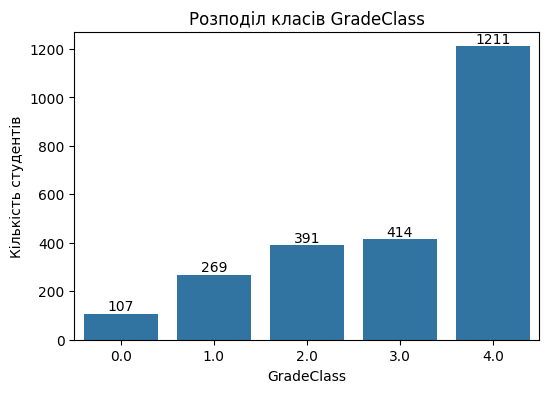

In [15]:
# Розподіл цільової змінної GradeClass (0 — A, 1 — B, 2 — C, 3 — D, 4 — F)
grade_counts = df['GradeClass'].value_counts().sort_index()
display(pd.DataFrame({'Кількість': grade_counts,
                      'Частка, %': (grade_counts / len(df) * 100).round(2)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='GradeClass', data=df, color='tab:blue')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Розподіл класів GradeClass')
plt.xlabel('GradeClass')
plt.ylabel('Кількість студентів')
plt.show()

**Висновок за оглядом даних:** набір містить 2 392 записи про студентів і 15 стовпців, усі числові (12 цілих і 3 дійсні: `StudyTimeWeekly`, `GPA`, `GradeClass`). Пропущених значень і дублікатів немає, `StudentID` унікальний, тож очищення не потрібне. Більшість ознак закодовані категорії (`Gender`, `Ethnicity`, `ParentalEducation`, `ParentalSupport`) або бінарні (`Tutoring`, `Sports`, `Music` тощо); неперервні — `StudyTimeWeekly` (0–20 год на тиждень), `Absences` (0–29) і `GPA` (0–4). Цільова змінна `GradeClass` сильно незбалансована: половина студентів (50,63 %) має найнижчу оцінку F (клас 4), а найвищу A (клас 0) — лише 4,47 %. Тому під час поділу використано стратифікацію.

**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [16]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # параметри масштабування — лише з train
X_test_scaled = scaler.transform(X_test)

print("Ознаки:", X.columns.tolist())
print("X_train:", X_train_scaled.shape, "| X_test:", X_test_scaled.shape)
print("Розподіл класів у train:", y_train.value_counts().sort_index().to_dict())
print("Розподіл класів у test: ", y_test.value_counts().sort_index().to_dict())

Ознаки: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']
X_train: (1913, 13) | X_test: (479, 13)
Розподіл класів у train: {0: 86, 1: 215, 2: 313, 3: 331, 4: 968}
Розподіл класів у test:  {0: 21, 1: 54, 2: 78, 3: 83, 4: 243}


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [17]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf,
                       cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

rf_best = grid_rf.best_estimator_
rf_test_acc = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print("Найкращі параметри:", grid_rf.best_params_)
print(f"Середня CV-точність: {grid_rf.best_score_:.4f}")
print(f"Тестова accuracy:    {rf_test_acc:.4f}")

Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy:    0.9102


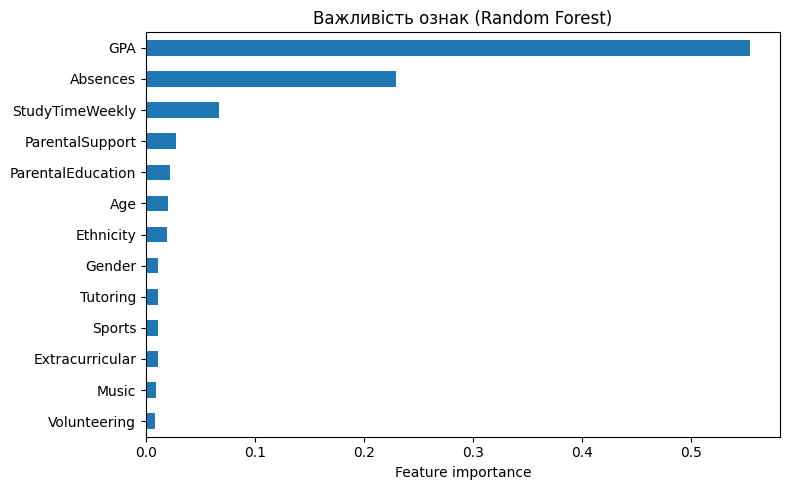

In [18]:
# Важливість ознак у найкращому Random Forest
importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='tab:blue')
plt.title('Важливість ознак (Random Forest)')
plt.xlabel('Feature importance')
plt.tight_layout()
plt.show()

### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [19]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
}

grid_lr = GridSearchCV(LogisticRegression(solver='saga', max_iter=5000, random_state=42),
                       param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

lr_best = grid_lr.best_estimator_
lr_test_acc = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print("Найкращі параметри:", grid_lr.best_params_)
print(f"Середня CV-точність: {grid_lr.best_score_:.4f}")
print(f"Тестова accuracy:    {lr_test_acc:.4f}")

Найкращі параметри: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy:    0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [20]:
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto'],
}

grid_svm = GridSearchCV(SVC(random_state=42), param_grid_svm,
                        cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

svm_best = grid_svm.best_estimator_
svm_test_acc = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print("Найкращі параметри:", grid_svm.best_params_)
print(f"Середня CV-точність: {grid_svm.best_score_:.4f}")
print(f"Тестова accuracy:    {svm_test_acc:.4f}")

Найкращі параметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8547
Тестова accuracy:    0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

,CV accuracy,Test accuracy
Модель,,
Random Forest,0.9211,0.9102
SVM,0.8547,0.8497
Logistic Regression,0.8024,0.8184


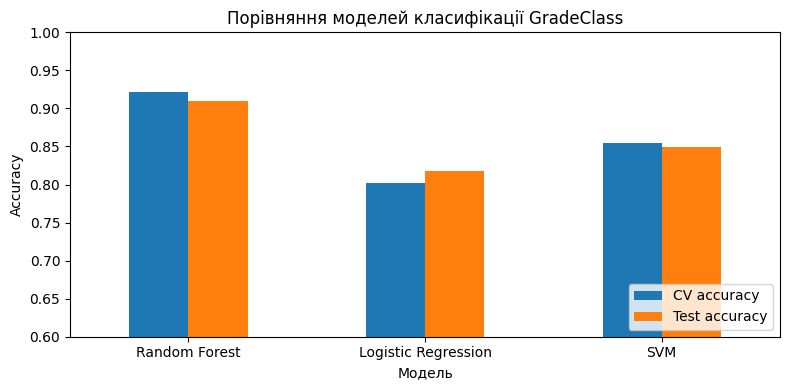

Обрано модель: Random Forest

Classification report на тестових даних:
              precision    recall  f1-score   support

           0      1.000     0.286     0.444        21
           1      0.821     0.852     0.836        54
           2      0.892     0.949     0.919        78
           3      0.892     0.892     0.892        83
           4      0.940     0.971     0.955       243

    accuracy                          0.910       479
   macro avg      0.909     0.790     0.809       479
weighted avg      0.913     0.910     0.903       479



In [21]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [grid_rf.best_score_, grid_lr.best_score_, grid_svm.best_score_],
    'Test accuracy': [rf_test_acc, lr_test_acc, svm_test_acc],
}).set_index('Модель')
display(results.round(4).sort_values('CV accuracy', ascending=False))

results.plot(kind='bar', figsize=(8, 4), rot=0, ylim=(0.6, 1))
plt.title('Порівняння моделей класифікації GradeClass')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Вибір моделі — за найкращою CV-точністю (тест для вибору не використовуємо)
best_model_name = results['CV accuracy'].idxmax()
best_clf = {'Random Forest': rf_best, 'Logistic Regression': lr_best, 'SVM': svm_best}[best_model_name]
print(f"Обрано модель: {best_model_name}")
print("\nClassification report на тестових даних:")
print(classification_report(y_test, best_clf.predict(X_test_scaled), digits=3))

**Висновок щодо класифікації:** найкращою за середньою CV-точністю виявилась модель **Random Forest** (`n_estimators=200, max_depth=10`): CV accuracy = 0,921, тестова accuracy = 0,910. SVM з лінійним ядром (`C=100`) посів друге місце (0,855 / 0,850), логістична регресія (`C=0.1, penalty='l1'`) — третє (0,802 / 0,818). Різниця між CV і тестом для всіх моделей не перевищує 1,6 п. п., тож перенавчання немає. Висока точність Random Forest пояснюється тим, що `GradeClass` фактично обчислюється з `GPA` за порогами, а дерева рішень якраз будують такі порогові правила; на графіку важливості ознак `GPA` суттєво переважає всі інші. Слабке місце моделі — найменший клас 0 (оцінка A): recall для нього лише 0,286 (з 21 студента правильно розпізнано 6), бо таких прикладів у навчальній вибірці всього 86.

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

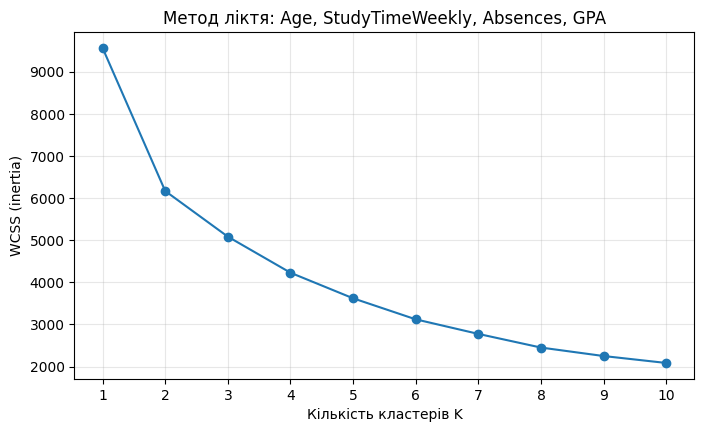

K,1,2,3,4,5,6,7,8,9,10
WCSS,9568.0,6170.5,5086.1,4229.4,3621.9,3122.2,2775.9,2451.7,2250.5,2085.6
"Зменшення, %",NaN,35.5,17.6,16.8,14.4,13.8,11.1,11.7,8.2,7.3


In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students = StandardScaler().fit_transform(df[cluster_features])

wcss_students = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_students)
    wcss_students.append(km.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 11), wcss_students, marker='o')
plt.title('Метод ліктя: Age, StudyTimeWeekly, Absences, GPA')
plt.xlabel('Кількість кластерів K')
plt.ylabel('WCSS (inertia)')
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

wcss_st_table = pd.DataFrame({'K': range(1, 11), 'WCSS': wcss_students})
wcss_st_table['Зменшення, %'] = (-wcss_st_table['WCSS'].pct_change() * 100).round(1)
display(wcss_st_table.round(1).set_index('K').T)

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

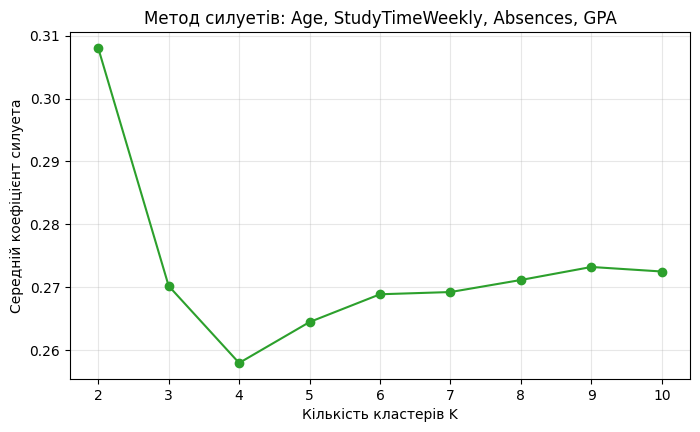

,2,3,4,5,6,7,8,9,10
Silhouette,0.308,0.27,0.258,0.264,0.269,0.269,0.271,0.273,0.272


Максимальний силует: K = 2 (0.308)


In [23]:
sil_students = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_students)
    sil_students.append(silhouette_score(X_students, labels))

plt.figure(figsize=(8, 4.5))
plt.plot(range(2, 11), sil_students, marker='o', color='tab:green')
plt.title('Метод силуетів: Age, StudyTimeWeekly, Absences, GPA')
plt.xlabel('Кількість кластерів K')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()

sil_st_table = pd.Series(sil_students, index=range(2, 11), name='Silhouette').round(3)
display(sil_st_table.to_frame().T)
print(f"Максимальний силует: K = {sil_st_table.idxmax()} ({sil_st_table.max():.3f})")

In [24]:
# Профілі кластерів для K з найкращим силуетом (середні значення у вихідних одиницях)
k_students = int(sil_st_table.idxmax())
student_labels = KMeans(n_clusters=k_students, n_init=10, random_state=42).fit_predict(X_students)

profile = df[cluster_features].assign(Кластер=student_labels).groupby('Кластер').mean().round(2)
profile['Кількість'] = pd.Series(student_labels).value_counts().sort_index()
display(profile)

# Довідково: середній GradeClass у кожному кластері (у кластеризації не використовувався)
print("Середній GradeClass за кластерами:",
      df.assign(Кластер=student_labels).groupby('Кластер')['GradeClass'].mean().round(2).to_dict())

,Age,StudyTimeWeekly,Absences,GPA,Кількість
Кластер,,,,,
0,16.47,9.29,21.62,1.15,1211
1,16.46,10.26,7.29,2.68,1181


Середній GradeClass за кластерами: {0: 3.82, 1: 2.13}


**Висновок щодо кластеризації студентів (чотири ознаки):** метод ліктя не має чіткого перегину: найбільше падіння WCSS — при переході від 1 до 2 кластерів (35,5 %), далі зменшення поступове (17,6 %, 16,8 %, 14,4 % …). Метод силуетів дає максимум при **K = 2** (0,308); для K = 3–10 силует майже сталий (0,26–0,27), тобто додаткові кластери не роблять розбиття якіснішим. Два кластери майже однакові за розміром (1 211 і 1 181) і розділяються головним чином за пропусками та успішністю: в одному — студенти з великою кількістю пропусків (у середньому 21,6) і низьким GPA (1,15), у другому — з малою кількістю пропусків (7,3) і вищим GPA (2,68). Вік і час на навчання у кластерах практично однакові. Невисоке значення силуету (≈ 0,3) показує, що групи не є чітко відокремленими.

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [26]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [27]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])
print("Ознаки для PCA:", X_all.columns.tolist())
print("Розмір:", X_all.shape)

Ознаки для PCA: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']
Розмір: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [28]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca_full = PCA(random_state=42)
pca_full.fit(X_all_scaled)
explained = pca_full.explained_variance_ratio_

explained_table = pd.DataFrame({
    'Компонента': np.arange(1, len(explained) + 1),
    'Частка дисперсії': explained,
    'Кумулятивна частка': np.cumsum(explained),
}).round(4)
display(explained_table.set_index('Компонента').T)

Компонента,1,2,3,4,5,6,7,8,9,10,11,12,13
Частка дисперсії,0.1525,0.0861,0.0827,0.0807,0.0786,0.0779,0.0763,0.0760,0.0744,0.0738,0.0717,0.0675,0.0018
Кумулятивна частка,0.1525,0.2386,0.3213,0.4020,0.4806,0.5586,0.6349,0.7109,0.7853,0.8591,0.9308,0.9982,1.0000


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Точка ліктя (кількість компонент): 2


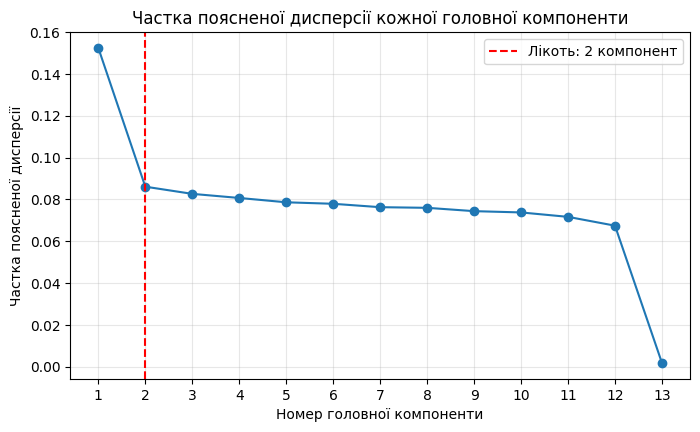

In [29]:
components = np.arange(1, len(explained) + 1)   # номери компонент: 1, 2, 3, ...
knee = KneeLocator(components, explained, curve='convex', direction='decreasing')
n_components = int(knee.knee)
print("Точка ліктя (кількість компонент):", n_components)

plt.figure(figsize=(8, 4.5))
plt.plot(components, explained, marker='o')
plt.axvline(n_components, color='red', linestyle='--', label=f'Лікоть: {n_components} компонент')
plt.title('Частка поясненої дисперсії кожної головної компоненти')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

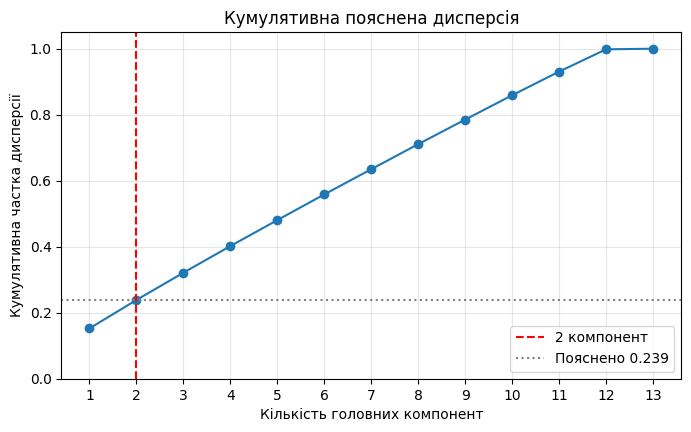

2 головні компоненти пояснюють частку дисперсії 0.2386 (23.9%)
Розмір даних після PCA: (2392, 2)


In [30]:
cumulative = np.cumsum(explained)
explained_by_selected = cumulative[n_components - 1]

plt.figure(figsize=(8, 4.5))
plt.plot(components, cumulative, marker='o')
plt.axvline(n_components, color='red', linestyle='--', label=f'{n_components} компонент')
plt.axhline(explained_by_selected, color='gray', linestyle=':',
            label=f'Пояснено {explained_by_selected:.3f}')
plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"{n_components} головні компоненти пояснюють частку дисперсії {explained_by_selected:.4f} "
      f"({explained_by_selected:.1%})")

pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_all_scaled)
print("Розмір даних після PCA:", X_pca.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [31]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

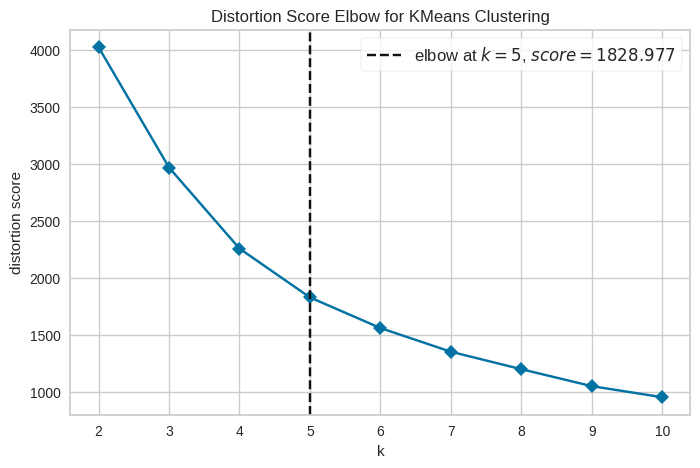

Точка ліктя за KElbowVisualizer: 5


In [32]:
plt.figure(figsize=(8, 5))
# force_model=True: yellowbrick 1.5 у нових версіях scikit-learn не розпізнає
# KMeans як кластеризатор і без цього параметра видає помилку
visualizer = KElbowVisualizer(KMeans(n_init=10, random_state=42), k=(2, 11),
                              timings=False, force_model=True)
visualizer.fit(X_pca)
visualizer.show()
print("Точка ліктя за KElbowVisualizer:", visualizer.elbow_value_)

In [33]:
# Додатково: силует на даних після PCA для того ж діапазону K
sil_pca = pd.Series(
    [silhouette_score(X_pca, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_pca))
     for k in range(2, 11)],
    index=range(2, 11), name='Silhouette (PCA)').round(3)
display(sil_pca.to_frame().T)
print(f"Максимальний силует після PCA: K = {sil_pca.idxmax()} ({sil_pca.max():.3f})")

,2,3,4,5,6,7,8,9,10
Silhouette (PCA),0.401,0.364,0.335,0.337,0.328,0.331,0.332,0.336,0.334


Максимальний силует після PCA: K = 2 (0.401)


## Висновки

**Завдання 1 (Iris).** Для трьох стандартизованих ознак метод ліктя показав перегин у межах K = 2–3 (найбільше падіння WCSS — 57,7 % при переході до K = 2), а метод силуетів дав чіткий максимум при K = 2 (0,552). Обрано два кластери: один повністю збігається з видом *setosa*, другий поєднує *versicolor* і *virginica*, які за розмірами чашолистка та пелюстки дуже схожі.

**Завдання 2, класифікація.** Найкращою моделлю за CV-точністю став Random Forest (CV accuracy 0,921, тестова accuracy 0,910); SVM дав 0,855 / 0,850, логістична регресія — 0,802 / 0,818. Висока якість пояснюється тим, що `GradeClass` визначається за значенням `GPA`, тому `GPA` є найважливішою ознакою.

**Завдання 2, кластеризація (Age, StudyTimeWeekly, Absences, GPA).** Ліктьова крива плавна, без виразного перегину, а метод силуетів вказує на K = 2 (0,308). Отримані кластери відрізняються передусім кількістю пропусків і GPA: «студенти з частими пропусками та низькою успішністю» і «студенти з рідкими пропусками та вищою успішністю».

**PCA (усі 13 ознак, крім `StudentID` і `GradeClass`).** `KneeLocator` за частками поясненої дисперсії визначив **2 головні компоненти**, які разом пояснюють лише частку **0,2386 (23,9 %)** дисперсії. Перша компонента пояснює 15,3 %, а кожна з наступних — лише 7–9 %, тобто ознаки слабо корельовані між собою і дані погано стискаються. На даних після PCA `KElbowVisualizer` знайшов лікоть при K = 5, тоді як силует після PCA, як і раніше, максимальний при K = 2 (0,401). Різні методи дали різні значення K (2 за силуетом, 2–3 або 5 за ліктем), тому ліктьовий метод слід розглядати як орієнтир, а остаточний вибір підтверджувати силуетом та змістовною інтерпретацією кластерів.

**Класифікація чи кластеризація.** У класифікації модель навчається на відомій цільовій змінній `GradeClass`, і її якість можна прямо перевірити за accuracy на тестовій вибірці. Кластеризація проводиться **без** `GradeClass`: алгоритм лише групує схожих студентів за ознаками, і отримані кластери не зобов'язані збігатися з оцінками. У нашому випадку два кластери все ж частково узгоджуються з успішністю (середній `GradeClass` 3,82 проти 2,13), бо до ознак входив `GPA`, але кластеризація не відповідає на питання «яку оцінку отримає студент», а лише показує природні групи в даних.